# Data Overview Processing and Cleaning 


## Importing Libraries

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
# we have imnported our libraries 

## Loading Data

In [2]:
df=pd.read_csv('austo_automobile.csv')

## Checking Data

In [3]:
df.head()

# here is the first 5 rows  

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
0,53,Male,Business,Married,Post Graduate,4,No,No,Yes,99300,70700.0,170000,61000,SUV
1,53,Femal,Salaried,Married,Post Graduate,4,Yes,No,Yes,95500,70300.0,165800,61000,SUV
2,53,Female,Salaried,Married,Post Graduate,3,No,No,Yes,97300,60700.0,158000,57000,SUV
3,53,Female,Salaried,Married,Graduate,2,Yes,No,Yes,72500,70300.0,142800,61000,SUV
4,53,Male,Salaried,Married,Post Graduate,3,No,No,Yes,79700,60200.0,139900,57000,SUV


In [4]:
df.tail()
# here is the last 5 rows and already we see Nan values 

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
1576,22,Male,Salaried,Single,Graduate,2,No,Yes,No,33300,0.0,33300,27000,Hatchback
1577,22,Male,Business,Married,Graduate,4,No,No,No,32000,NaN,32000,31000,Hatchback
1578,22,Male,Business,Single,Graduate,2,No,Yes,No,32900,0.0,32900,30000,Hatchback
1579,22,Male,Business,Married,Graduate,3,Yes,Yes,No,32200,NaN,32200,24000,Hatchback
1580,22,Male,Salaried,Married,Graduate,4,No,No,No,31600,0.0,31600,31000,Hatchback


### Checking Structure


In [5]:
df.shape


(1581, 14)

 here we have 1581 records with 14 columns 

### Checking Data Types


In [6]:
df.info()
# lets check the types of the data 

<class 'pandas.DataFrame'>
RangeIndex: 1581 entries, 0 to 1580
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1581 non-null   int64  
 1   Gender            1528 non-null   str    
 2   Profession        1581 non-null   str    
 3   Marital_status    1581 non-null   str    
 4   Education         1581 non-null   str    
 5   No_of_Dependents  1581 non-null   int64  
 6   Personal_loan     1581 non-null   str    
 7   House_loan        1581 non-null   str    
 8   Partner_working   1581 non-null   str    
 9   Salary            1581 non-null   int64  
 10  Partner_salary    1475 non-null   float64
 11  Total_salary      1581 non-null   int64  
 12  Price             1581 non-null   int64  
 13  Make              1581 non-null   str    
dtypes: float64(1), int64(5), str(8)
memory usage: 173.1 KB


### Checking for and Treating Missing values and Data irregularities 

checking how many Unique values exists for all variables 


In [7]:
df.nunique()

Age                  33
Gender                4
Profession            2
Marital_status        2
Education             2
No_of_Dependents      5
Personal_loan         2
House_loan            2
Partner_working       2
Salary              538
Partner_salary      149
Total_salary        754
Price                53
Make                  3
dtype: int64

Investigating the unque values for each Variable as gender seems to have 4  unique values but expected number of unique values is meant to be 2


In [8]:
for var in df.columns:
    print(var)
    print(df[var].unique())
    print()

Age
[53 52 50 49 47 46 45 51 54 48 44 43 42 41 40 39 38 37 36 35 34 33 32 31
 30 29 28 27 26 25 24 23 22]

Gender
<StringArray>
['Male', 'Femal', 'Female', nan, 'Femle']
Length: 5, dtype: str

Profession
<StringArray>
['Business', 'Salaried']
Length: 2, dtype: str

Marital_status
<StringArray>
['Married', 'Single']
Length: 2, dtype: str

Education
<StringArray>
['Post Graduate', 'Graduate']
Length: 2, dtype: str

No_of_Dependents
[4 3 2 1 0]

Personal_loan
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

House_loan
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Partner_working
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Salary
[99300 95500 97300 72500 79700 79800 80900 79100 89400 83700 81600 81300
 77400 77600 74100 87600 86800 95100 92600 98400 72700 84600 88000 85400
 78000 87900 81900 88500 87700 98300 94900 91100 74500 81700 84700 82200
 79600 77700 72100 96600 72800 73500 90000 87100 90300 72200 78300 90200
 79500 73400 90600 93900 80600 85100 82300 79200 70600 79300

Lets see the irregularity with Gender


In [9]:
df['Gender'].unique()

<StringArray>
['Male', 'Femal', 'Female', nan, 'Femle']
Length: 5, dtype: str

Clearly a typo error which simply needs to replace the Incorrect Spelling with Correct spelling

In [10]:
df['Gender'] = df['Gender'].replace({'Femal':'Female','Femle':'Female'})

Checking Unique Values again 
df['Gender'].unique()

In [11]:
df['Gender'].unique()

<StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str

Now Dealing with Missing values 

In [12]:
df.isnull().sum()


Age                   0
Gender               53
Profession            0
Marital_status        0
Education             0
No_of_Dependents      0
Personal_loan         0
House_loan            0
Partner_working       0
Salary                0
Partner_salary      106
Total_salary          0
Price                 0
Make                  0
dtype: int64

Filling Nan Gender value with Most commonly occuring value ie modal value to fill out categorical missing values

In [13]:
df['Gender'] = df['Gender'].fillna(value = df['Gender'].mode()[0])

Lets find out how many Partners with Nan Partner_salary are working and how many are not working 

In [14]:
nan_working_partner = ((df['Partner_salary'].isna()) & (df['Partner_working']=='Yes')).sum()
print(nan_working_partner,"rows in Partner_salary with Parnter working as 'Yes'")
nan_not_working_partner = ((df['Partner_salary'].isna()) & (df['Partner_working']=='No')).sum()
print(nan_not_working_partner,"rows in Partner_salary with Parnter working as 'No'")

16 rows in Partner_salary with Parnter working as 'Yes'
90 rows in Partner_salary with Parnter working as 'No'


Filling Partner_salary According to Parnter_working Status of 'Yes' or 'No' 
- If 'Yes' Partner_salary = Total_salary - Salary
- If 'No' Partner_salary= 0

In [15]:
df.loc[(df['Partner_salary'].isna()) & (df['Partner_working']=='Yes'),'Partner_salary'] = df['Total_salary'] - df['Salary']
df.loc[(df['Partner_salary'].isna()) & (df['Partner_working']=='No'),'Partner_salary'] = 0

Checking for anty pending missing values

In [16]:
df.isnull().sum()

Age                 0
Gender              0
Profession          0
Marital_status      0
Education           0
No_of_Dependents    0
Personal_loan       0
House_loan          0
Partner_working     0
Salary              0
Partner_salary      0
Total_salary        0
Price               0
Make                0
dtype: int64

Checking for Duplicates

In [17]:
df.duplicated().sum()

np.int64(0)

### Stastical Summary

In [18]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1581.0,31.922201,8.425978,22.0,25.0,29.0,38.0,54.0
No_of_Dependents,1581.0,2.457938,0.943483,0.0,2.0,2.0,3.0,4.0
Salary,1581.0,60392.220114,14674.825044,30000.0,51900.0,59500.0,71800.0,99300.0
Partner_salary,1581.0,19233.776091,19670.391171,0.0,0.0,25100.0,38100.0,80500.0
Total_salary,1581.0,79625.996205,25545.857768,30000.0,60500.0,78000.0,95900.0,171000.0
Price,1581.0,35597.722960,13633.636545,18000.0,25000.0,31000.0,47000.0,70000.0


# Exploratory Data Analysis

## Univariate Analysis

### Age

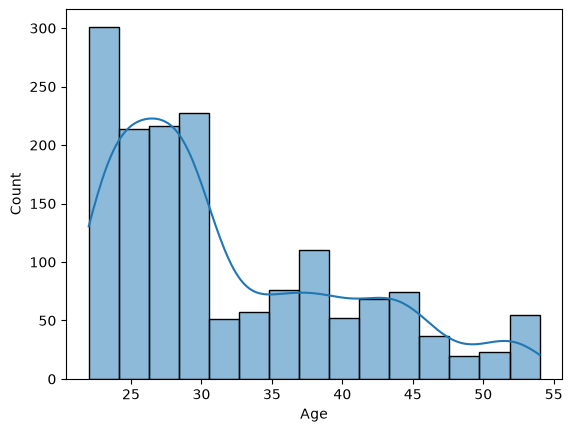

In [19]:
sns.histplot(data=df,x = 'Age',kde = True);

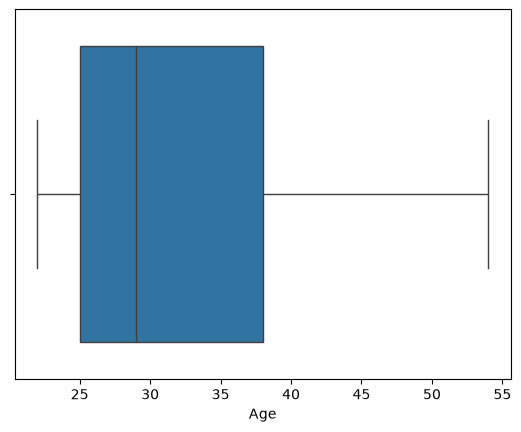

In [20]:
sns.boxplot(data=df,x='Age');

### Gender

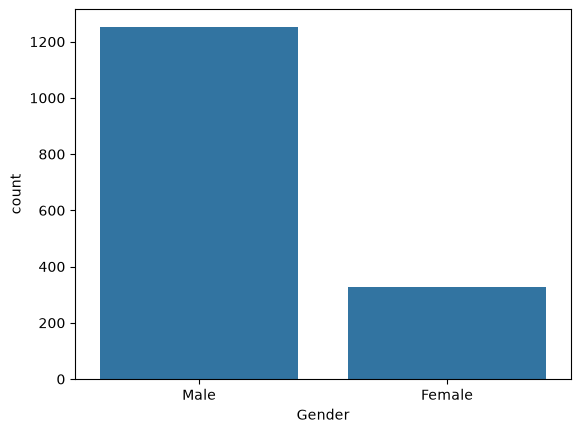

In [21]:
sns.countplot(data = df , x = 'Gender');

### Profession

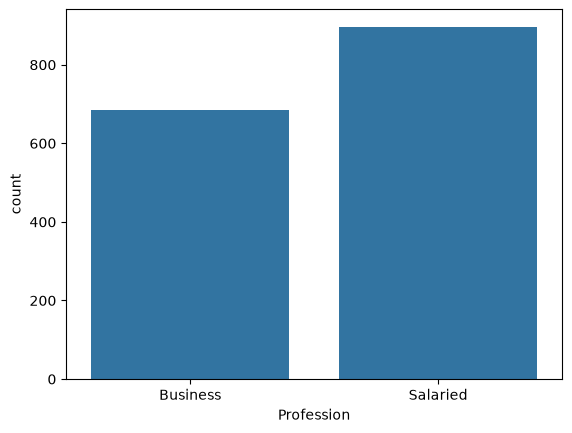

In [22]:
sns.countplot(data = df , x = 'Profession');

### Marital_status

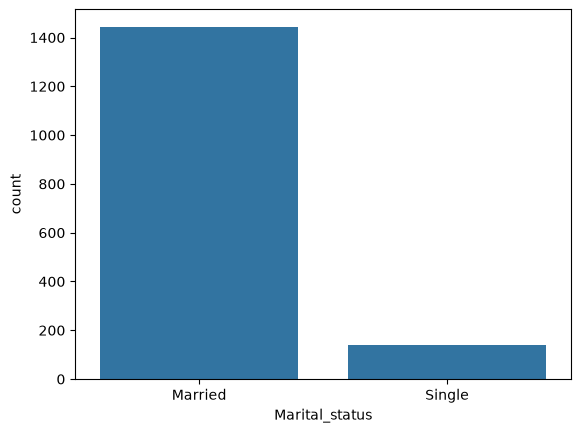

In [23]:
sns.countplot(data = df , x = 'Marital_status');

### Education

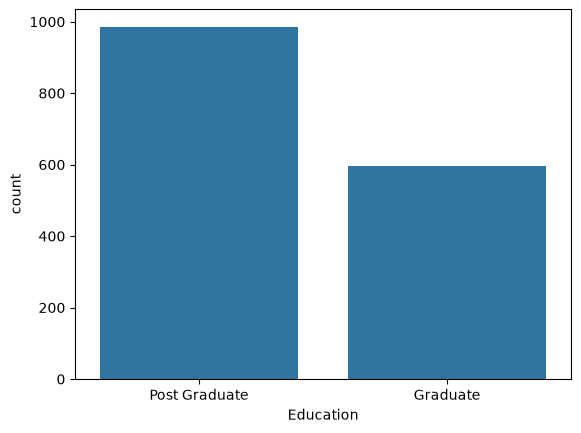

In [24]:
sns.countplot(data = df , x = 'Education');

### No_of_Dependents

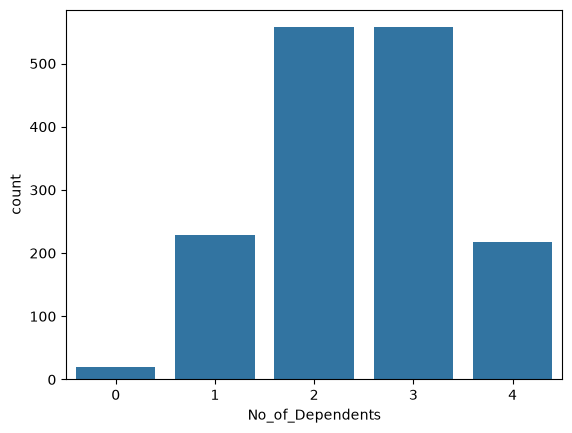

In [25]:
sns.countplot(data = df , x = 'No_of_Dependents');

### Personal_loan

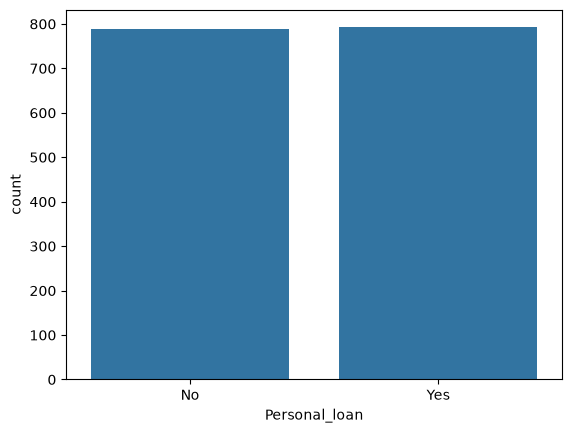

In [26]:
sns.countplot(data = df , x = 'Personal_loan');

### House_loan

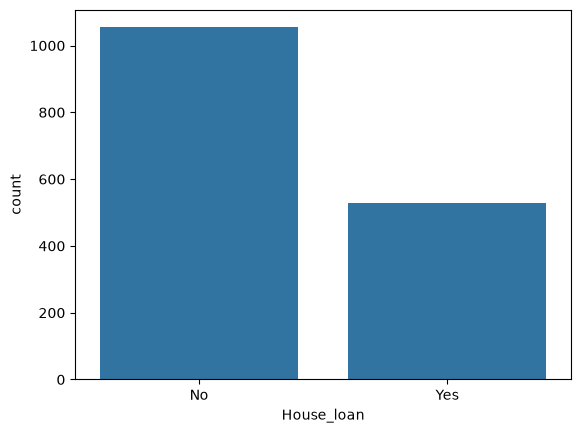

In [27]:
sns.countplot(data = df , x = 'House_loan');

### Partner_working

<Axes: xlabel='Partner_working', ylabel='count'>

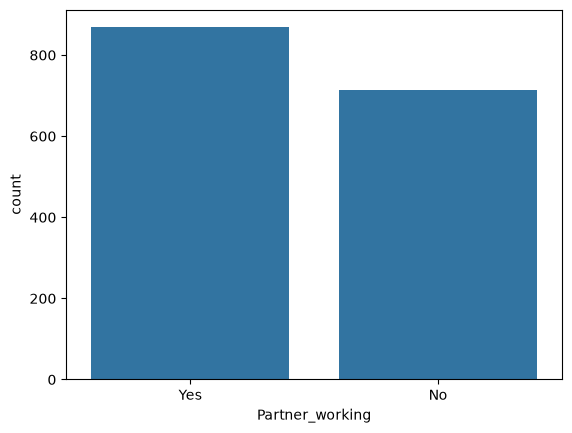

In [28]:
sns.countplot(data = df , x = 'Partner_working')

### Salary

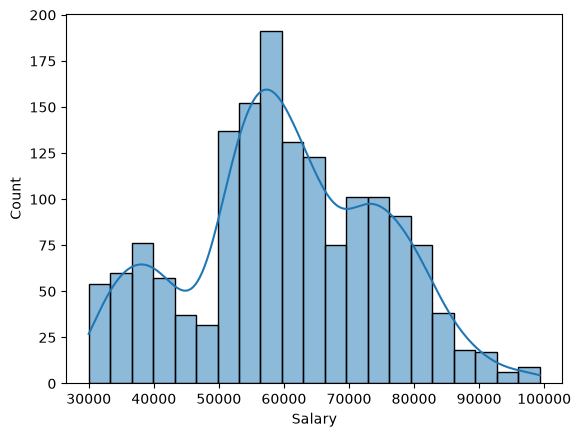

In [29]:
sns.histplot(data  = df, x='Salary' , kde = True);

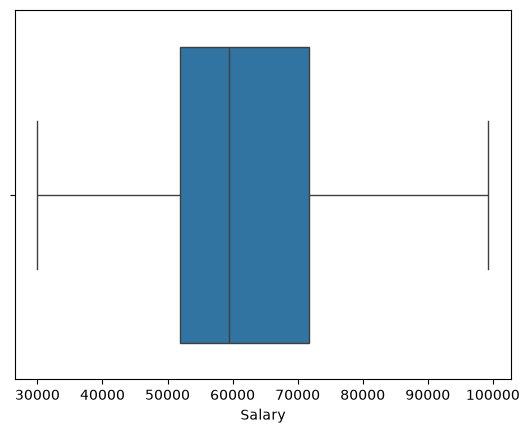

In [30]:
sns.boxplot( data = df, x = 'Salary');

### Partner_salary

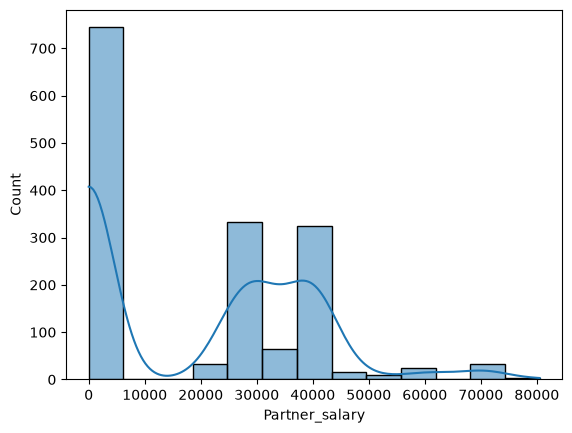

In [31]:
sns.histplot(data  = df, x='Partner_salary' , kde = True);

<Axes: xlabel='Partner_salary'>

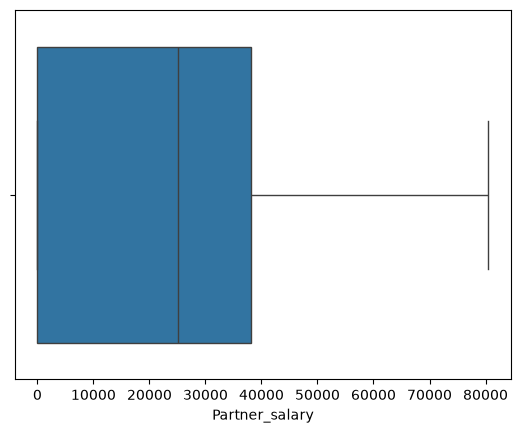

In [32]:
sns.boxplot(data  = df, x='Partner_salary')

### Total_salary

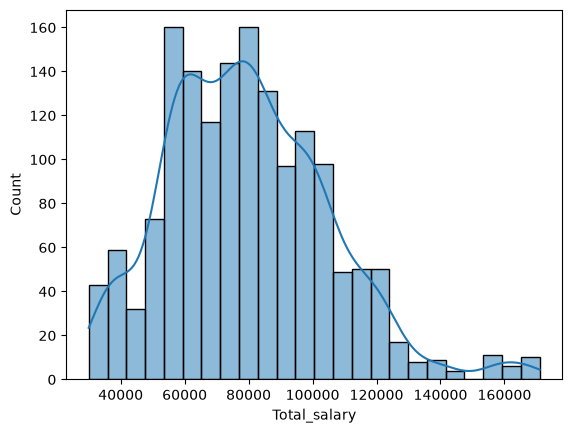

In [33]:
sns.histplot(data  = df, x='Total_salary' , kde = True);

<Axes: xlabel='Total_salary'>

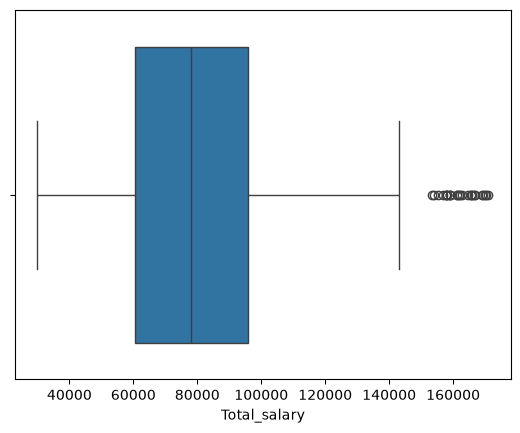

In [34]:
sns.boxplot(data  = df, x='Total_salary' )

### Price

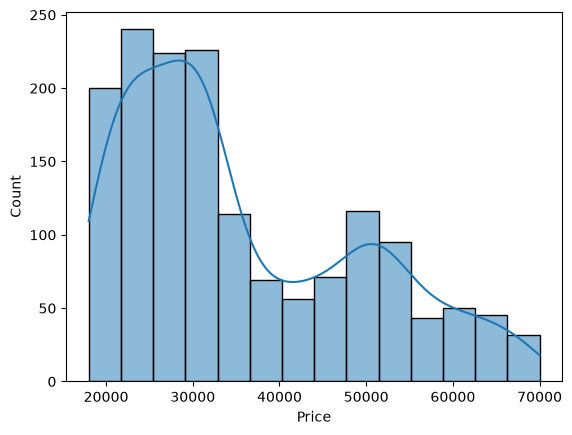

In [35]:
sns.histplot(data = df, x ='Price', kde = True);

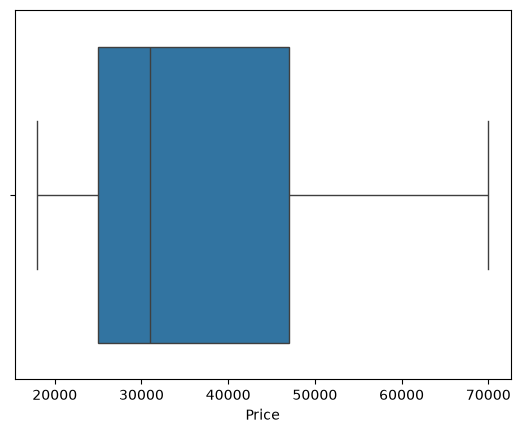

In [36]:
sns.boxplot(data = df , x='Price');


### Make

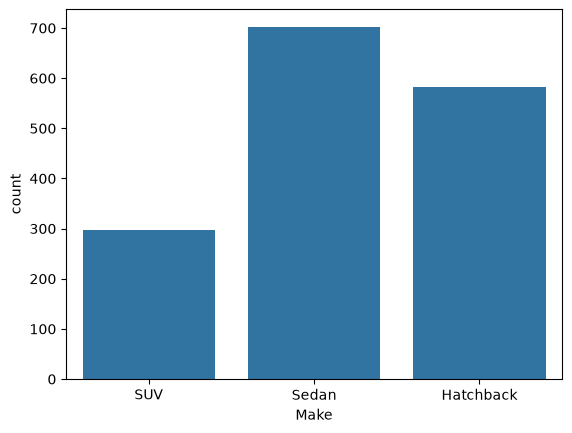

In [37]:
sns.countplot(data = df , x = 'Make');


## Bivariate Analysis

### Numerical vs Numerical

#### Age vs Price

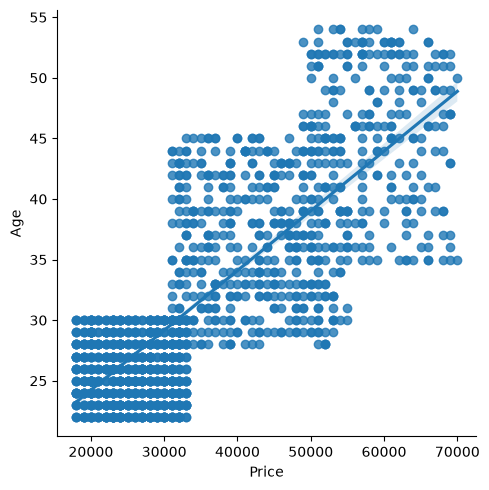

In [38]:
sns.lmplot(data=df, x='Price',y='Age');

In [39]:
# The highest Price that majority of customers below 30 choose is 33k
df[(df['Age']<=25)]['Price'].max()

np.int64(33000)

#### No_of_Dependents vs Price

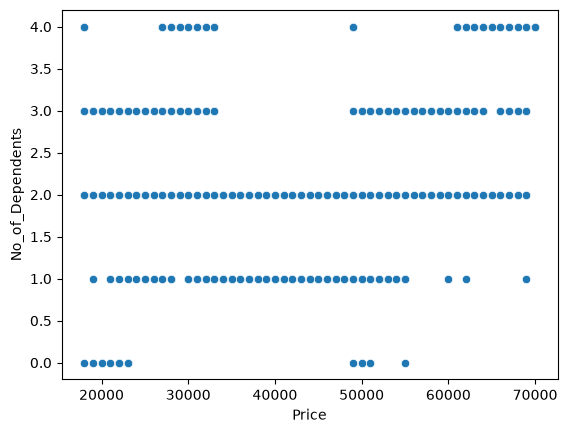

In [40]:
sns.scatterplot(data=df, x='Price',y='No_of_Dependents');

#### Salary vs Price

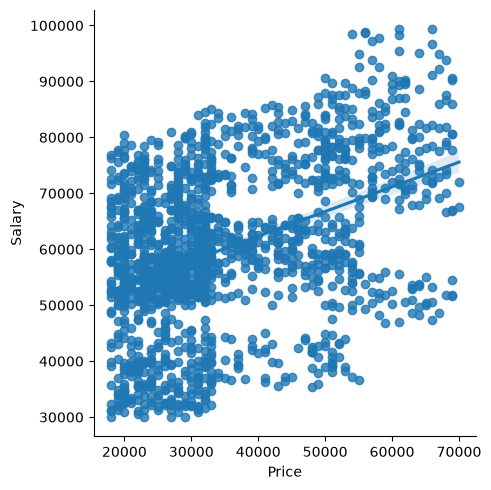

In [41]:
sns.lmplot(data=df, x='Price',y='Salary');

#### Partner_salary vs Price

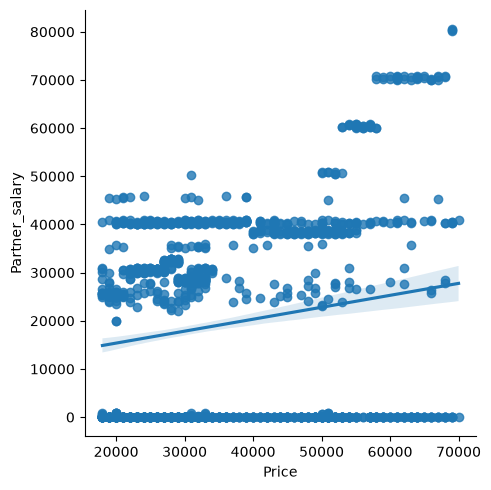

In [42]:
sns.lmplot(data=df, x='Price',y='Partner_salary');

#### Total_salary vs Price

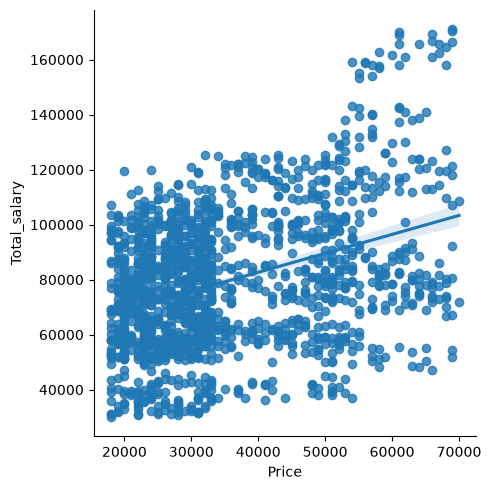

In [43]:
sns.lmplot(data=df, x='Price',y='Total_salary');


### Corelation 

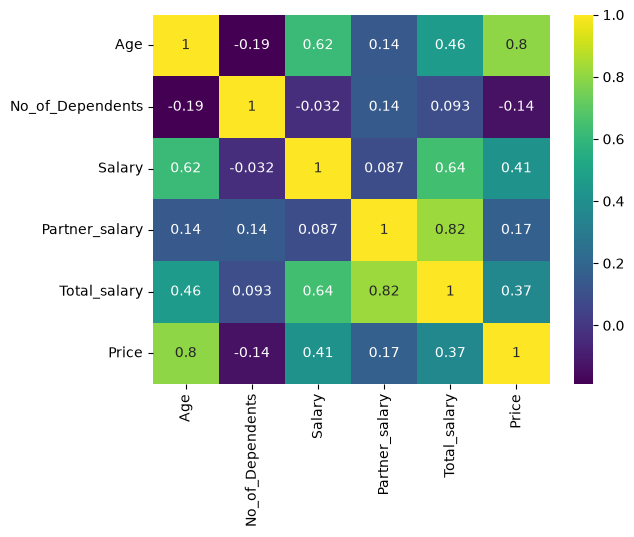

In [44]:
sns.heatmap(df.corr(numeric_only= True),annot=True, cmap='viridis');

### Categorical vs Numerical

#### Age vs Make

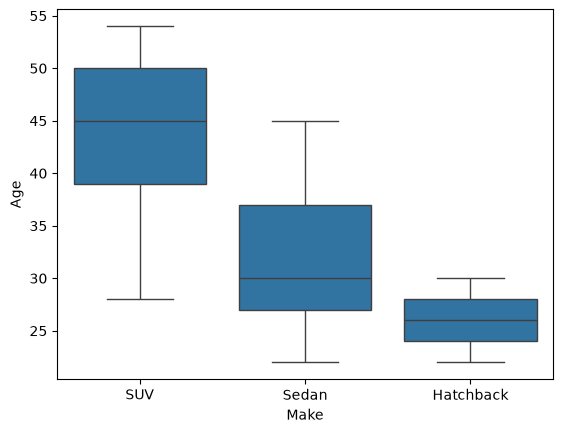

In [45]:
sns.boxplot(data = df , x = 'Make', y = 'Age');

#### No_of_Dependents vs Make

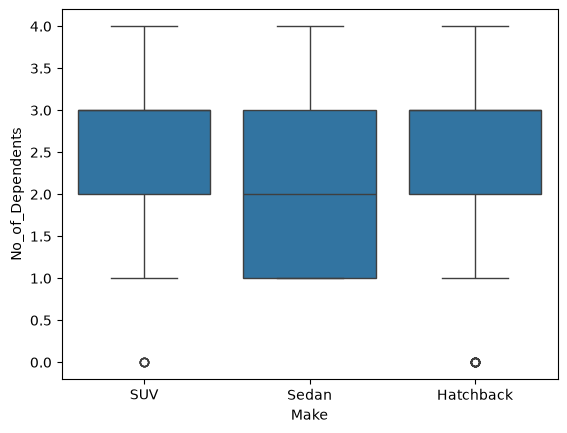

In [46]:
sns.boxplot(data = df , x = 'Make', y = 'No_of_Dependents');

#### Salary vs Make

<Axes: xlabel='Make', ylabel='Salary'>

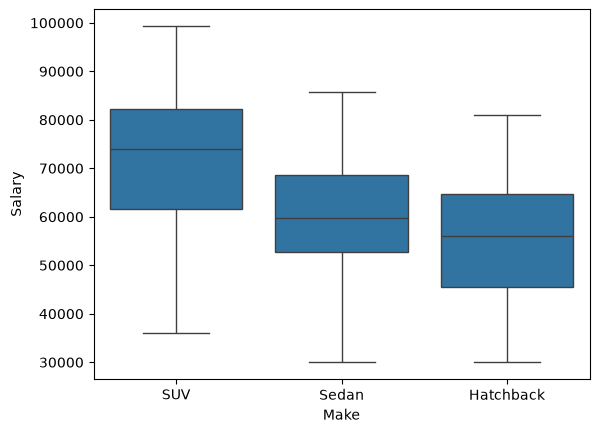

In [47]:
sns.boxplot(data = df , x = 'Make', y = 'Salary')

#### Partner_salary vs Make

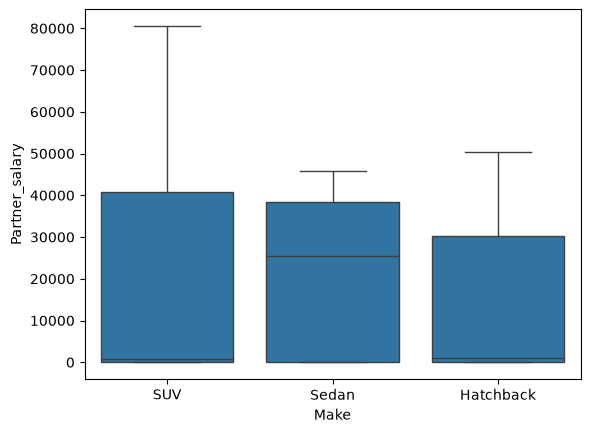

In [48]:
sns.boxplot(data = df , x = 'Make', y = 'Partner_salary');

#### Total_salary vs Make

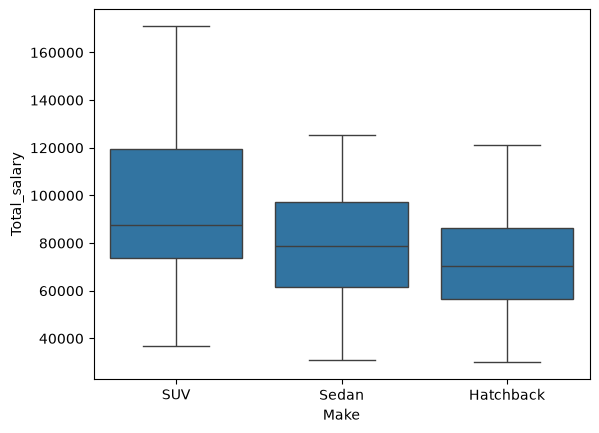

In [49]:
sns.boxplot(data = df , x = 'Make', y = 'Total_salary');

### Price vs Make

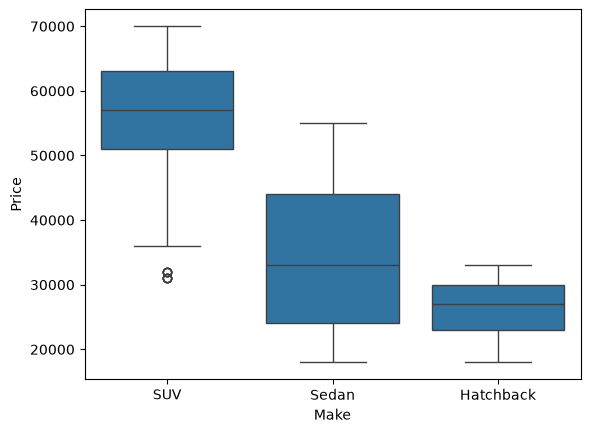

In [50]:
sns.boxplot(data = df , x = 'Make', y = 'Price');

# Key Questions

## 1. Do men tend to prefer SUVs more compared to women?

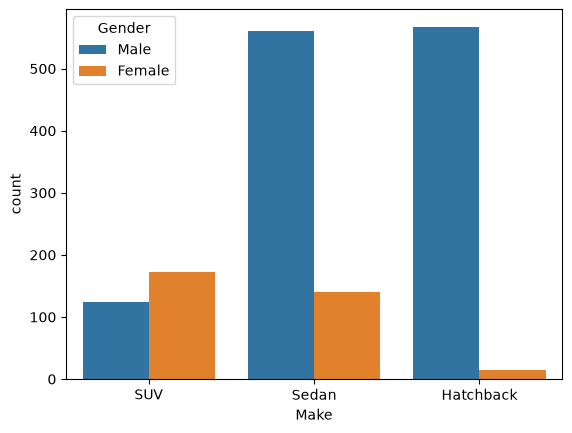

In [51]:
sns.countplot(data = df, x = 'Make', hue = 'Gender');

## 2. What is the likelihood of a salaried person buying a Sedan?

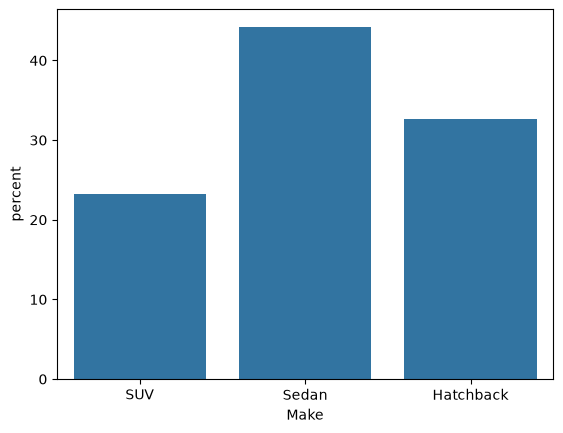

In [52]:
sns.countplot(data = df[df['Profession']=='Salaried'], x = 'Make',  stat = 'percent');

## 3. What evidence or data supports Sheldon Cooper's claim that a salaried male is an easier target for a SUV sale over a Sedan sale?

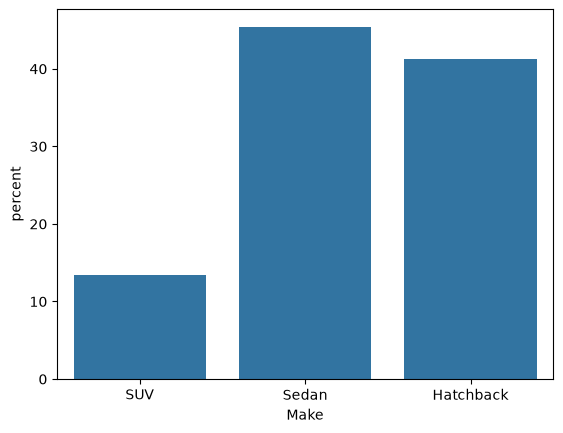

In [53]:
sns.countplot(data = df[(df['Profession']=='Salaried') & (df['Gender']=='Male')], x = 'Make',  stat = 'percent');

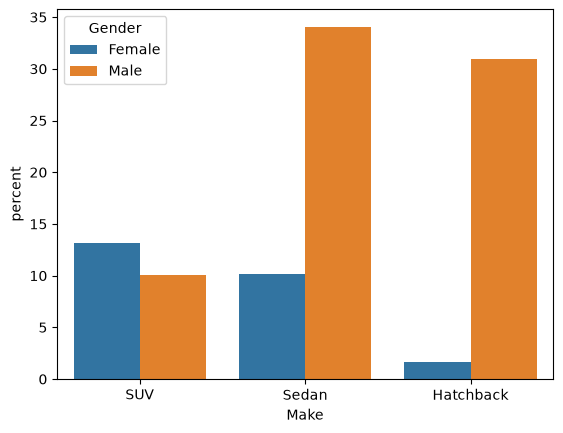

In [54]:
sns.countplot(data = df[(df['Profession']=='Salaried') ], x = 'Make',hue='Gender',  stat = 'percent');

## 4. How does the the amount spent on purchasing automobiles vary by gender?

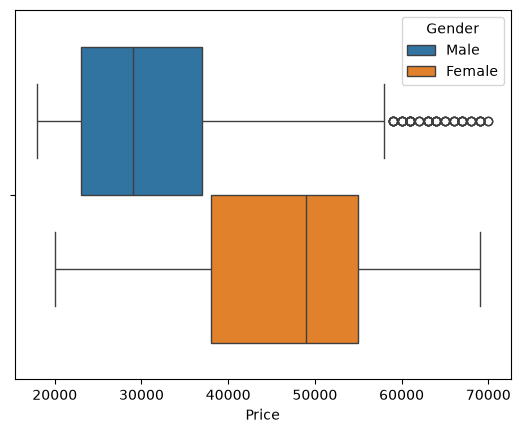

In [55]:
sns.boxplot(data = df, x='Price', hue='Gender');

## 5. How much money was spent on purchasing automobiles by individuals who took a personal loan?

In [56]:
total_money_by_personal_loan_customers = df.loc[(df['Personal_loan']=='Yes'), 'Price'].sum()

print("Total money that was spent on purchasing automobiles by individuals who took a personal loan = ",total_money_by_personal_loan_customers)

Total money that was spent on purchasing automobiles by individuals who took a personal loan =  27290000


## 6. How does having a working partner influence the purchase of higher-priced cars?

<Axes: xlabel='Price'>

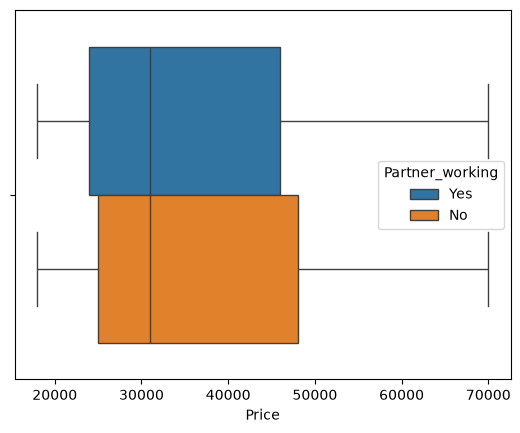

In [57]:
sns.boxplot(data=df, x='Price',hue = 'Partner_working')

# Additional Visualization


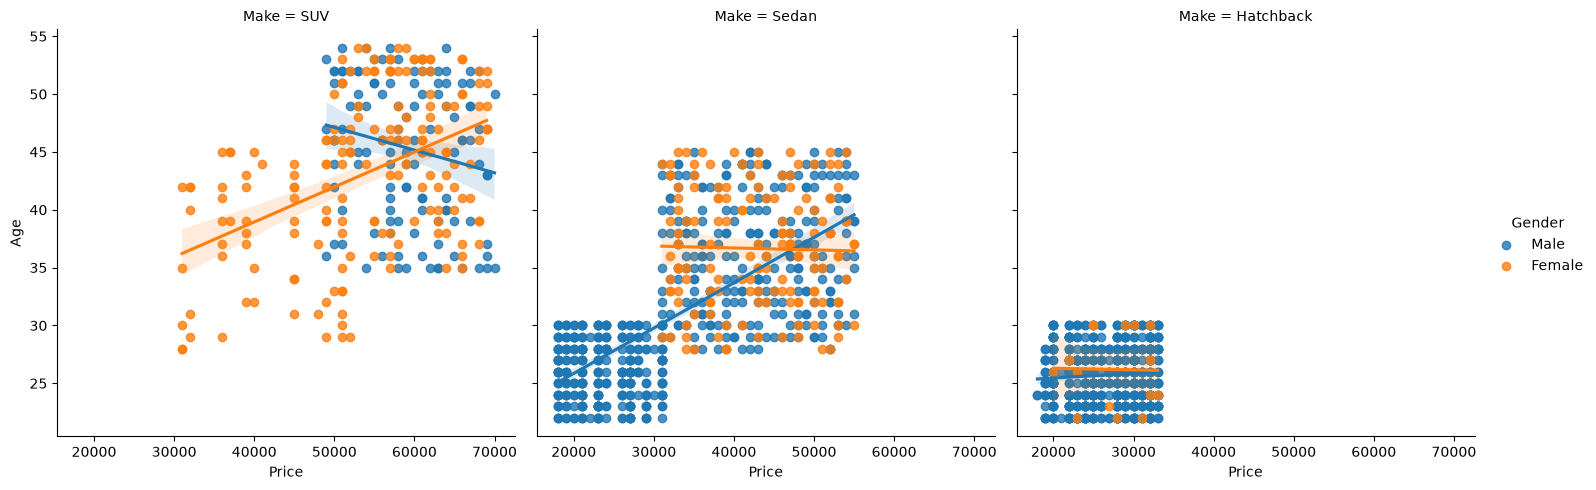

In [58]:
sns.lmplot(data=df, x='Price',y='Age', hue = 'Gender', col = 'Make')  